# The MMG backend: `adapt`, `discretize_levelset`, `mesh_domain` and `move`

[MMG](https://www.mmgtools.org/) remeshes simplicial meshes: `mmg2d` planar triangles, `mmgs` surfaces and `mmg3d` tetrahedra (roadmap 3.2, [`doc/mmg.md`](../../doc/mmg.md)). meshio++ links it as an optional, bring-your-own backend (`-DMESHIOPLUSPLUS_WITH_MMG=ON`, `build/build-mmg.sh`): it is LGPL-3.0, so the published wheels do not carry it, and every operation here raises `NotImplementedError` naming the flag without it. `move` also needs an MMG built with ELAS (GPL-3.0).

This notebook runs each of the four operations on a small 2-D case: adapting a rectangle to the metric of an analytic field's Hessian, cutting a square along a level set, triangulating an annulus from its boundary, and moving a hole through a mesh.

In [1]:
import os
import subprocess
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def triangles(mesh):
    return np.concatenate([np.asarray(b.data) for b in mesh.cells if b.type == 'triangle'])


def render2d(ax, mesh, title, values=None, cmap='viridis'):
    """A planar triangle mesh seen from above: PyVista off-screen embedded through
    matplotlib, or matplotlib's own triangulation without GL."""
    xy = np.asarray(mesh.points)[:, :2]
    tri = triangles(mesh)
    if pv is not None:
        grid = to_pyvista(mp.Mesh(np.column_stack([xy, np.zeros(len(xy))]), [('triangle', tri)]))
        pl = pv.Plotter(off_screen=True, window_size=(700, 700))
        if values is not None:
            grid.cell_data['v'] = values
            pl.add_mesh(grid, scalars='v', cmap=cmap, show_edges=True, edge_color='#1f4e79',
                        line_width=0.4, show_scalar_bar=False)
        else:
            pl.add_mesh(grid, color='#2ec4b6', show_edges=True, edge_color='#1f4e79', line_width=0.4)
        pl.view_xy()
        pl.camera.zoom(1.3)
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        if values is not None:
            ax.tripcolor(xy[:, 0], xy[:, 1], tri, facecolors=values, cmap=cmap, edgecolors='#1f4e79', linewidth=0.2)
        else:
            ax.triplot(xy[:, 0], xy[:, 1], tri, color='#1f4e79', linewidth=0.3)
        ax.set_aspect('equal')
        ax.axis('off')
    ax.set_title(title)


print('MMG:', mp.has_mmg(), '| ELAS:', mp.has_mmg_elas())

No GL available: rendering with matplotlib.
MMG: True | ELAS: True


## `adapt`: a rectangle to the metric of a Hessian

`hessian` differentiates a field twice, `metric_from_hessian` turns the Hessian into the anisotropic metric `M = c/error |H|` (clamped to `[hmin, hmax]`, in the lower-triangle order of a Medit `.sol`), and `adapt` remeshes to it. The field `tanh(20 (x - 0.5))` varies across one line only, so the triangles come out long and thin along it, and coarse elsewhere.

metric components per point: 6
{'library': 'mmg2d', 'status': 'success', 'num_points_in': 625, 'num_points_out': 315, 'num_elements_in': 1152, 'num_elements_out': 537}
aspect ratio: min 1 mean 57.7


meshio warning [mmg.cpp:1512] adapt: point_data 'u' is dropped: the points are new (compose with interpolate)
meshio warning [mmg.cpp:1512] adapt: point_data 'u:hessian' is dropped: the points are new (compose with interpolate)


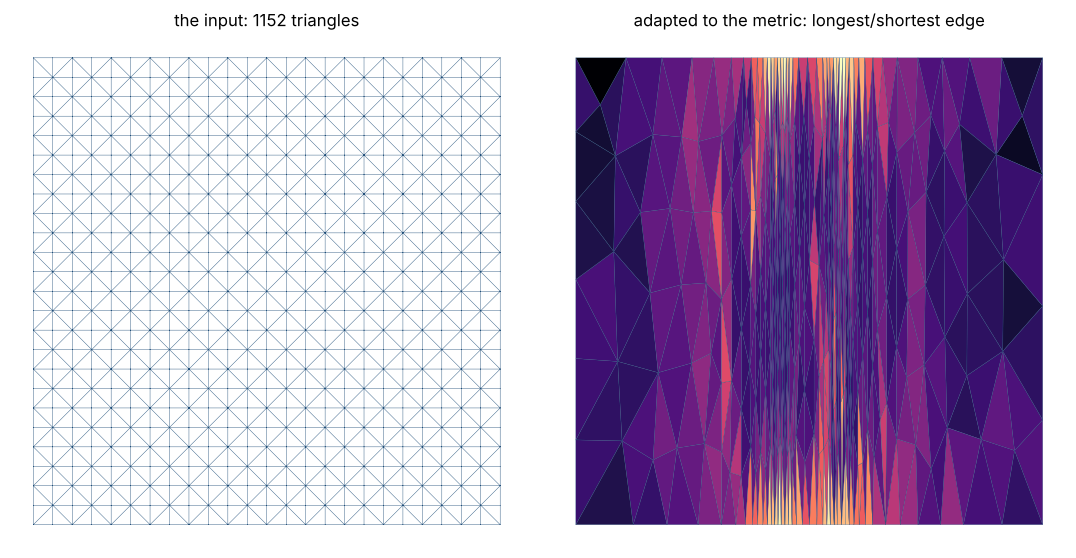

In [2]:
square = mp.rectangle(dims=(24, 24), cell_type='triangle')
square.point_data['u'] = np.tanh(20 * (square.points[:, 0] - 0.5))
with_h = mp.hessian(square, 'u', location='point')
with_m = mp.metric_from_hessian(with_h, 'u:hessian', error=2e-3, hmin=2e-3, hmax=0.2)
print('metric components per point:', with_m.point_data['metric'].shape[1])

if mp.has_mmg():
    adapted, report = mp.adapt(with_m, metric='metric', return_report=True)
    print({k: report[k] for k in ('library', 'status', 'num_points_in', 'num_points_out',
                                   'num_elements_in', 'num_elements_out')})
    print('aspect ratio: min %.3g mean %.3g' % (report['quality']['min'], report['quality']['mean']))
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    render2d(axes[0], square, 'the input: %d triangles' % len(triangles(square)))
    tri = triangles(adapted)
    xy = adapted.points[tri][:, :, :2]
    edges = np.linalg.norm(xy - np.roll(xy, 1, axis=1), axis=2)
    render2d(axes[1], adapted, 'adapted to the metric: longest/shortest edge',
             values=np.log10(edges.max(1) / edges.min(1)), cmap='magma')
    plt.tight_layout()
    plt.show()
else:
    print('No MMG in this build: adapt raises NotImplementedError naming MESHIOPLUSPLUS_WITH_MMG.')

## `discretize_levelset`: a disc cut out of a square

The isovalue of a level set, here the signed distance to a circle of radius 0.5, becomes a conformal interface: both sides are remeshed, the elements carry `medit:ref` 3 inside and 2 outside, with the cell regions `inside` and `outside` and the side region `interface` between them.

regions: {'inside': ('cell', 278), 'outside': ('cell', 1217), 'interface': ('side', 42)}
area inside: 0.7682 (pi r^2 = 0.7854)


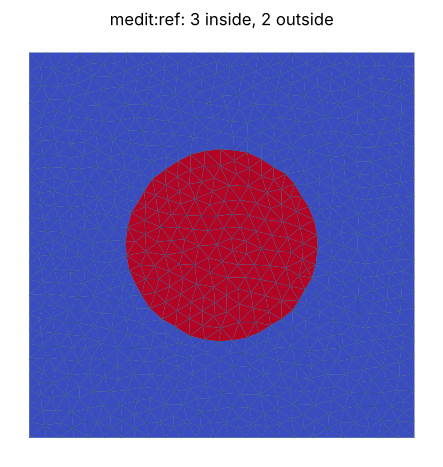

In [3]:
if mp.has_mmg():
    sq = mp.rectangle(dims=(12, 12), size=(2, 2), origin=(-1, -1, 0), cell_type='triangle')
    phi = np.linalg.norm(sq.points[:, :2], axis=1) - 0.5
    cut, report = mp.discretize_levelset(sq, phi, hmax=0.08, return_report=True)
    refs = np.concatenate(cut.cell_data['medit:ref'])
    names = {r.name: (r.kind, len(r.entries)) for r in cut.regions}
    print('regions:', {k: v for k, v in names.items() if k in ('inside', 'outside', 'interface')})
    tri = triangles(cut)
    p = cut.points[tri][:, :, :2]
    a, c = p[:, 1] - p[:, 0], p[:, 2] - p[:, 0]
    area = 0.5 * np.abs(a[:, 0] * c[:, 1] - a[:, 1] * c[:, 0])
    print('area inside: %.4f (pi r^2 = %.4f)' % (area[refs == 3].sum(), np.pi * 0.25))
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    render2d(ax, cut, 'medit:ref: 3 inside, 2 outside', values=refs.astype(float), cmap='coolwarm')
    plt.show()

## `mesh_domain`: an annulus from its two circles

`MMG2D_mmg2dmesh` triangulates every region a set of lines encloses. MMG has no notion of a hole, so `holes` names the regions to leave out by a point inside each; each region kept is a cell region `subdomain:<k>`, and the lines' regions come back as side regions of the triangles.

without the hole point: 2 subdomains; with it: 1 subdomain, 1 hole


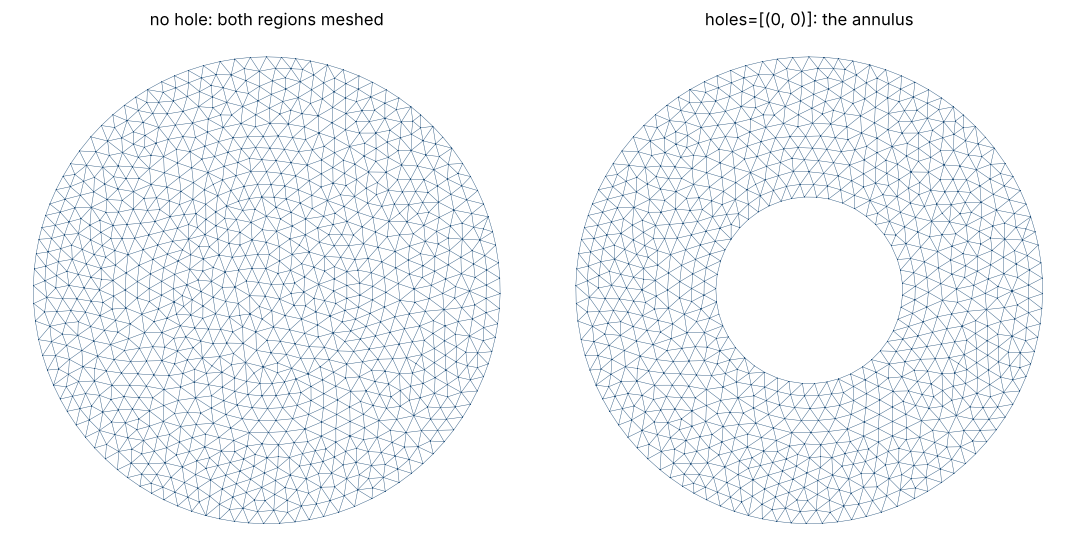

In [4]:
if mp.has_mmg():
    th = np.linspace(0, 2 * np.pi, 49)[:-1]
    ring = np.column_stack([np.cos(th), np.sin(th)])
    lines = [[i, (i + 1) % 48] for i in range(48)] + [[48 + i, 48 + (i + 1) % 48] for i in range(48)]
    boundary = mp.Mesh(np.vstack([ring, 0.4 * ring]), [('line', np.array(lines))])
    boundary.regions = [mp.Region('outer', 'cell', np.arange(48)), mp.Region('inner', 'cell', np.arange(48, 96))]
    both, rb = mp.mesh_domain(boundary, hsiz=0.06, return_report=True)
    annulus, ra = mp.mesh_domain(boundary, hsiz=0.06, holes=[(0, 0)], return_report=True)
    print('without the hole point: %d subdomains; with it: %d subdomain, %d hole'
          % (rb['num_subdomains'], ra['num_subdomains'], ra['num_holes']))
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    render2d(axes[0], both, 'no hole: both regions meshed')
    render2d(axes[1], annulus, 'holes=[(0, 0)]: the annulus')
    plt.tight_layout()
    plt.show()

## `move`: a hole carried through a mesh

MMG's Lagrangian mode moves the boundary facets of the named regions by a displacement, extends it inward by linear elasticity (ELAS) and keeps the rest of the boundary in place, swapping edges as the mesh deforms. Here the square hole of a holed square moves 0.15 to the right: every triangle stays right side out and the area is unchanged.

mmg2d, success: smallest signed area 1.68e-04, total 0.9600 (1 - 0.04 = 0.96)


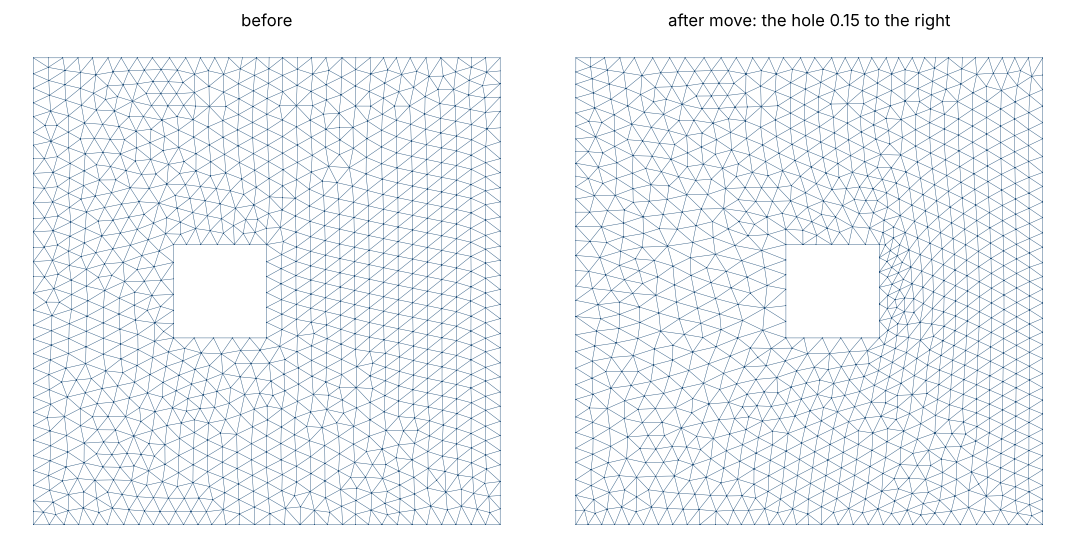

In [5]:
if mp.has_mmg() and mp.has_mmg_elas():
    outer = [[0, 0], [1, 0], [1, 1], [0, 1]]
    inner = [[0.3, 0.4], [0.5, 0.4], [0.5, 0.6], [0.3, 0.6]]
    lines = [[i, (i + 1) % 4] for i in range(4)] + [[4 + i, 4 + (i + 1) % 4] for i in range(4)]
    b = mp.Mesh(np.array(outer + inner, float), [('line', np.array(lines))])
    b.regions = [mp.Region('outer', 'cell', np.arange(4)), mp.Region('hole', 'cell', np.arange(4, 8))]
    holed = mp.mesh_domain(b, hsiz=0.035, holes=[(0.4, 0.5)])
    x, y = holed.points[:, 0], holed.points[:, 1]
    on_hole = (x > 0.29) & (x < 0.51) & (y > 0.39) & (y < 0.61)
    d = np.zeros((len(holed.points), 2))
    d[on_hole, 0] = 0.15
    moved, report = mp.move(holed, d, 'hole', return_report=True)

    def signed_areas(m):
        p = m.points[triangles(m)][:, :, :2]
        a, c = p[:, 1] - p[:, 0], p[:, 2] - p[:, 0]
        return 0.5 * (a[:, 0] * c[:, 1] - a[:, 1] * c[:, 0])

    s = signed_areas(moved)
    print('%s, %s: smallest signed area %.2e, total %.4f (1 - 0.04 = 0.96)'
          % (report['library'], report['status'], s.min(), s.sum()))
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    render2d(axes[0], holed, 'before')
    render2d(axes[1], moved, 'after move: the hole 0.15 to the right')
    plt.tight_layout()
    plt.show()
elif mp.has_mmg():
    print('This MMG has no ELAS: move raises NotImplementedError naming it.')